# Polynomial Regression with SciKit-Learn
### Moeletsi Mangaliso Namane
### 16 November 2026

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
# We continue with advertisement data as described in ISLR
path = r"G:\My Drive\INTRO TO ML AND DATA SCIENCE\data\Advertising.csv"

df = pd.read_csv(path)
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [4]:
X = df.drop("sales",axis=1)
y = df["sales"]

## Polynomial Regression

Polynomial regression is a method that models the relationship between an independent variable $x$ and a dependent variable $y$ using a polynomial function of the form

$$
f(x) = \beta_0 + \beta_1 x + \beta_2 x^2 + \cdots + \beta_d x^d, \tag{1}
$$

where $d$ is the degree of the polynomial and $\beta_0, \beta_1, \dots, \beta_d$ are the corresponding coefficients. The objective is to determine the set of coefficients $\boldsymbol{\beta}$ that provides the best fit to the observed data, typically estimated via ordinary least squares (OLS) to minimise the sum of squared residuals between the observed values and predictions.

In statistics, a more realistic model is given as

$$
y = f(x) + \epsilon, \tag{2}
$$

where $\epsilon$ represents the irreducible error (inherent noise) in the data, typically assumed to have a conditional mean of zero, $\mathbb{E}[\epsilon \mid x] = 0$. This means that $f(x)$ describes the average value of $y$ for a given $x$, while individual observations may differ from this average due to noise. Although a model can fit the training data without error, nonzero inherent noise means that no predictor using $x$ alone can guarantee error-free predictions of new observations.

The predicted function is given as

$$
\hat{y} = \hat{f}(x) = \hat{\beta}_0 + \hat{\beta}_1 x + \hat{\beta}_2 x^2 + \cdots + \hat{\beta}_d x^d, \tag{3}
$$

where $\hat{\beta}_0, \hat{\beta}_1, \dots, \hat{\beta}_d$ are the coefficients estimated from the observed data. The noise term is not included in the predicted function because the model estimates the average response rather than the unpredictable variation in individual observations.

----
We will go from the equation in the form (shown here as if we only had one x feature):

$$\hat{y} = \beta_0 + \beta_1x_1 + \epsilon $$

and create more features from the original x feature for some *d* degree of polynomial.

$$\hat{y} = \beta_0 + \beta_1x_1 + \beta_1x^2_1 +  ... + \beta_dx^d_1 + \epsilon$$

Then we can call the linear regression model on it, since in reality, we're just treating these new polynomial features x^2, x^3, ... x^d as new features. Obviously we need to be careful about choosing the correct value of *d* , the degree of the model. Our metric results on the test set will help us with this!

### A Side Note
we have multiple X features, not just a single one as in the formula above, so in reality, the PolynomialFeatures will also take *interaction* terms into account for example, if an input sample is two dimensional and of the form [a, b], the degree-2 polynomial features are [1, a, b, a^2, ab, b^2].

In [5]:
from sklearn.preprocessing import PolynomialFeatures

In [6]:
# include_bias = False, removes the feature 1s that go with beta_0
polynomial_converter = PolynomialFeatures(degree=2,include_bias=False)
# Converter "fits" to data, in this case, reads in every X column
# Then it "transforms" and ouputs the new polynomial data
poly_features = polynomial_converter.fit_transform(X)
poly_features.shape

(200, 9)

In [7]:
X.shape # This shows that polyfeatures created higher degree features, combaring to the output of the cell above.

(200, 3)

In [8]:
X.iloc[0]

TV           230.1
radio         37.8
newspaper     69.2
Name: 0, dtype: float64

In [9]:
np.set_printoptions(suppress=True, precision=2)
poly_features[0]

array([  230.1 ,    37.8 ,    69.2 , 52946.01,  8697.78, 15922.92,
        1428.84,  2615.76,  4788.64])

$$x_1,x_2,x_3,\\
x_{1}^2\;,\; x_1\cdot x_2\; ,\; x_1 \cdot x_3,\\
 x_2^2\;,\;x_2\cdot x_3\;,x_3^2$$

In [10]:
display(poly_features[0][:3])
display(poly_features[0][:3]**2)
print(230.1 * 37.8 , 230.1 * 69.2 , 37.8 * 69.2 )

array([230.1,  37.8,  69.2])

array([52946.01,  1428.84,  4788.64])

8697.779999999999 15922.92 2615.7599999999998


In [11]:
# Train | Test Split

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size=0.3, random_state=101)

In [14]:
from sklearn.linear_model import LinearRegression


# fit_intercept takes care of fitting the beta_0 coefficients, we did not include it when getting polyfeatures.
# recall include_bias=False
model =  LinearRegression(fit_intercept=True)

# Fitting the model on training data (training data because we want to evaluate model perfomance fairly)
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ 0.05, 0.01, 0.01,..., 0. , 0. ,-0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.126
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](9,)","[304692.02, 51558.83, 29086.88,..., 226.23, 61.34, 40.79]"


# Evaluation on the Test Set
### Calculate Perfomance on Test Set
We want to fairly evaluate our model, so we will get perfomance metrics on the test set. 

In [15]:
test_predictions = model.predict(X_test)

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [17]:
mae = mean_absolute_error(y_test,test_predictions)
mse = mean_squared_error(y_test,test_predictions)
rmse = np.sqrt(mse)
display(mae,mse,rmse,df['sales'].mean())

0.48967980448035886

0.44175055104033895

np.float64(0.6646431757269)

np.float64(14.0225)

## Comparison with Simple Linear Regression
### **Result on the test set**

* Simple Linear Regression:
    * MAE: 1.213
    * RMSE: 1.516

* Polynomial 2-degree:
    * MAE: 0.4896
    * RMSE: 0.664



## Choosing a model
### Adjusting Parameters

How do we know if this performance is satisfactory? What if a higher order would improve perfomance even more? Another question is how high is too high? We plot higher order polynomials in a loop and plot out the root mean square error.

We will utilize a for loop for the following:

    1. Create different order polynomial X data
    2. Split that polynomial data for train/test
    3. Fit on the training data
    4. Report back the metrics on both the train and test results
    5. Plot these results and explore overfitting

In [19]:
# Training error per degree (ascending)
train_rmse_errors = []
# Test error per degree (ascending)
test_rmse_errors = []

for d in range(1,10):

    # Create X poly dataset for degree 'd', the interaction features multiplying and stuff.
    polynomial_converter = PolynomialFeatures(degree=d,include_bias=False)
    poly_features = polynomial_converter.fit_transform(X)

    # To spliting this new poly dataset
    X_train, X_test, y_train, y_test = train_test_split(poly_features, y, test_size=0.3, random_state=101)

    # Train on these new polynomial features
    model = LinearRegression(fit_intercept=True) 
    model.fit(X_train,y_train)

    # Predict on both train and test
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Error calculation

    # For training set errors
    train_RMSE = np.sqrt(mean_squared_error(y_train,train_pred))

    # For test set errors
    test_RMSE = np.sqrt(mean_squared_error(y_test,test_pred))

    # putting errors in an array
    train_rmse_errors.append(train_RMSE)
    test_rmse_errors.append(test_RMSE)

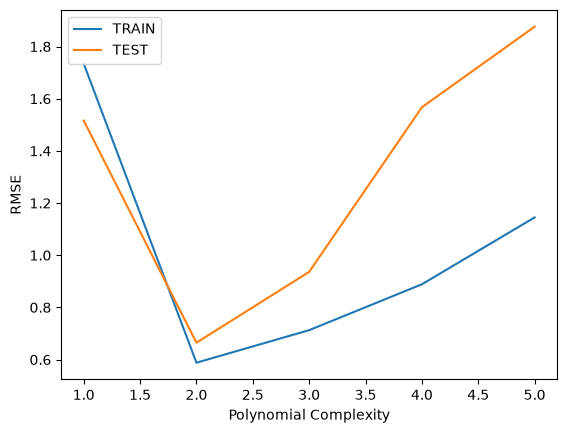

In [24]:
plt.plot(range(1,6),train_rmse_errors[:5],label='TRAIN')
plt.plot(range(1,6),test_rmse_errors[:5],label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("RMSE")
plt.legend()
plt.show()

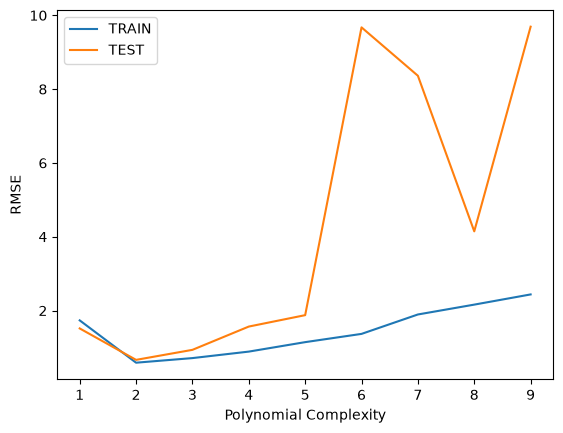

In [27]:
plt.plot(range(1,10),train_rmse_errors,label='TRAIN')
plt.plot(range(1,10),test_rmse_errors,label='TEST')
plt.xlabel("Polynomial Complexity")
plt.ylabel("RMSE")
plt.legend();

## Finalizing Model Choice
### This is how we proceed:
1. Choose final parameters based on test metrics
2. Retrain on all data
3. Save Polynomial Converter object
4. Save model

In [30]:
# Based on our chat degree 2 has the least amount of error
# We fit a polynomial of degree 2 to all the data.
final_poly_converter = PolynomialFeatures(degree=2,include_bias=False)
final_model = LinearRegression()
# The first argument in .fit is the polynomial features.
final_model.fit(final_poly_converter.fit_transform(X),y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[0.05,0.02,0.01,...,0. ,0. ,0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.085
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](9,)","[364459.28, 60804. , 33888.94,..., 278.18, 77.76, 49.28]"


In [31]:
from joblib import dump, load

In [32]:
dump(final_model, 'sales_poly_model.joblib') 

['sales_poly_model.joblib']

In [33]:
dump(final_poly_converter,'poly_converter.joblib')

['poly_converter.joblib']